In [3]:
from google.colab import files

uploaded = files.upload()
# using this module to import file

Saving electricity.csv to electricity.csv


In [4]:
import pandas as pd
import numpy as np
df = pd.read_csv("electricity.csv")

print(df.head())
print(df.shape)
print(df.columns)

# importing pandas for dataframing and numpy for manipulating

   date   day    period  nswprice  nswdemand  vicprice  vicdemand  transfer  \
0   0.0  b'2'  0.000000  0.056443   0.439155  0.003467   0.422915  0.414912   
1   0.0  b'2'  0.021277  0.051699   0.415055  0.003467   0.422915  0.414912   
2   0.0  b'2'  0.042553  0.051489   0.385004  0.003467   0.422915  0.414912   
3   0.0  b'2'  0.063830  0.045485   0.314639  0.003467   0.422915  0.414912   
4   0.0  b'2'  0.085106  0.042482   0.251116  0.003467   0.422915  0.414912   

     class  
0    b'UP'  
1    b'UP'  
2    b'UP'  
3    b'UP'  
4  b'DOWN'  
(45312, 9)
Index(['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice',
       'vicdemand', 'transfer', 'class'],
      dtype='object')


In [5]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45312 entries, 0 to 45311
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       45312 non-null  float64
 1   day        45312 non-null  object 
 2   period     45312 non-null  float64
 3   nswprice   45312 non-null  float64
 4   nswdemand  45312 non-null  float64
 5   vicprice   45312 non-null  float64
 6   vicdemand  45312 non-null  float64
 7   transfer   45312 non-null  float64
 8   class      45312 non-null  object 
dtypes: float64(7), object(2)
memory usage: 3.1+ MB
None
date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64


In [6]:
#just finding difference in data
print(df.head())
print(df["day"].unique())
print(df["class"].value_counts())

   date   day    period  nswprice  nswdemand  vicprice  vicdemand  transfer  \
0   0.0  b'2'  0.000000  0.056443   0.439155  0.003467   0.422915  0.414912   
1   0.0  b'2'  0.021277  0.051699   0.415055  0.003467   0.422915  0.414912   
2   0.0  b'2'  0.042553  0.051489   0.385004  0.003467   0.422915  0.414912   
3   0.0  b'2'  0.063830  0.045485   0.314639  0.003467   0.422915  0.414912   
4   0.0  b'2'  0.085106  0.042482   0.251116  0.003467   0.422915  0.414912   

     class  
0    b'UP'  
1    b'UP'  
2    b'UP'  
3    b'UP'  
4  b'DOWN'  
["b'2'" "b'3'" "b'4'" "b'5'" "b'6'" "b'7'" "b'1'"]
class
b'DOWN'    26075
b'UP'      19237
Name: count, dtype: int64


In [7]:
print(df["vicprice"].describe())

count    45312.000000
mean         0.003467
std          0.010213
min          0.000000
25%          0.002277
50%          0.003467
75%          0.003467
max          1.000000
Name: vicprice, dtype: float64


In [8]:
print("Unique Victoria prices:", df["vicprice"].unique())

print(df[["vicprice", "vicdemand", "nswprice", "nswdemand"]].corr())
# checking the price range of victoria and nsw

Unique Victoria prices: [0.003467 0.003232 0.003145 ... 0.006894 0.00677  0.005675]
           vicprice  vicdemand  nswprice  nswdemand
vicprice   1.000000   0.127553  0.286072   0.086393
vicdemand  0.127553   1.000000  0.307275   0.668501
nswprice   0.286072   0.307275  1.000000   0.304952
nswdemand  0.086393   0.668501  0.304952   1.000000


In [9]:
import numpy as np

df["time"] = pd.to_timedelta(
    (df["period"] * 24 * 60).round().astype(int),
    unit="m"
)

In [10]:
period_price = df.groupby("period")["vicprice"].mean()

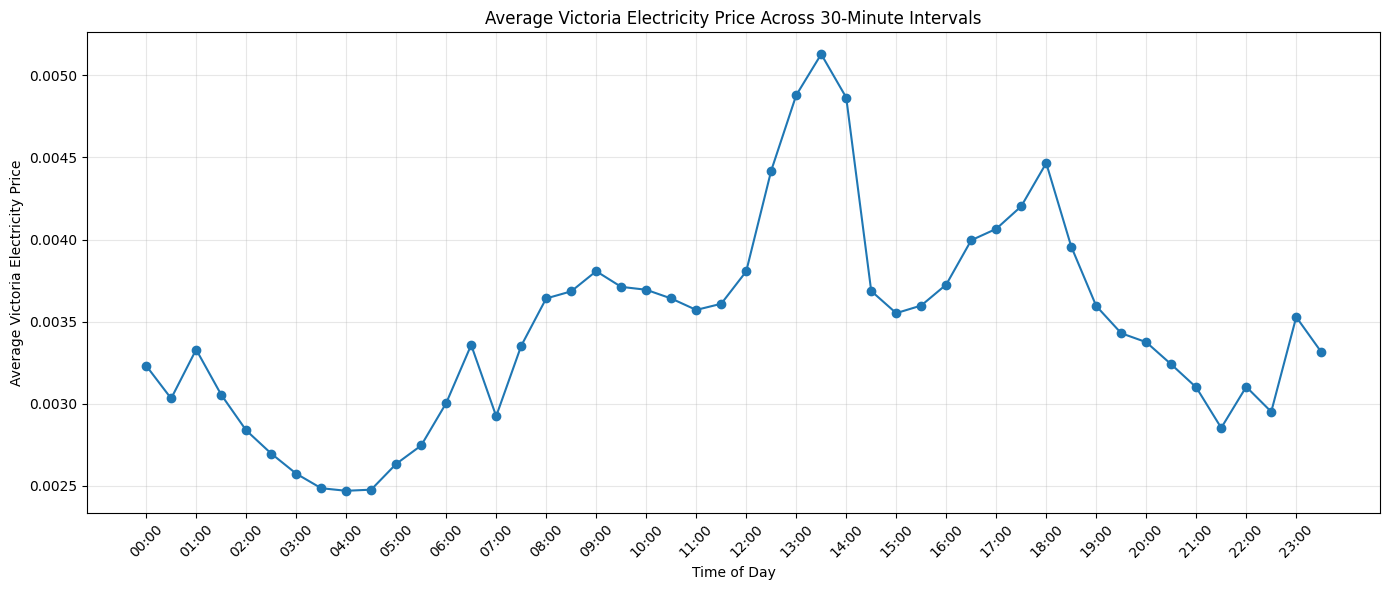

In [11]:
#used graphing to visualize the change in price for every 30min in victoria town
import matplotlib.pyplot as plt

# Create 48 half-hour labels
time_labels = pd.date_range(
    "00:00",
    "23:30",
    freq="30min"
).strftime("%H:%M")

plt.figure(figsize=(14, 6))

plt.plot(
    range(48),
    period_price.values,
    marker="o"
)

plt.title("Average Victoria Electricity Price Across 30-Minute Intervals")
plt.xlabel("Time of Day")
plt.ylabel("Average Victoria Electricity Price")

plt.xticks(
    range(0, 48, 2),
    time_labels[::2],
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

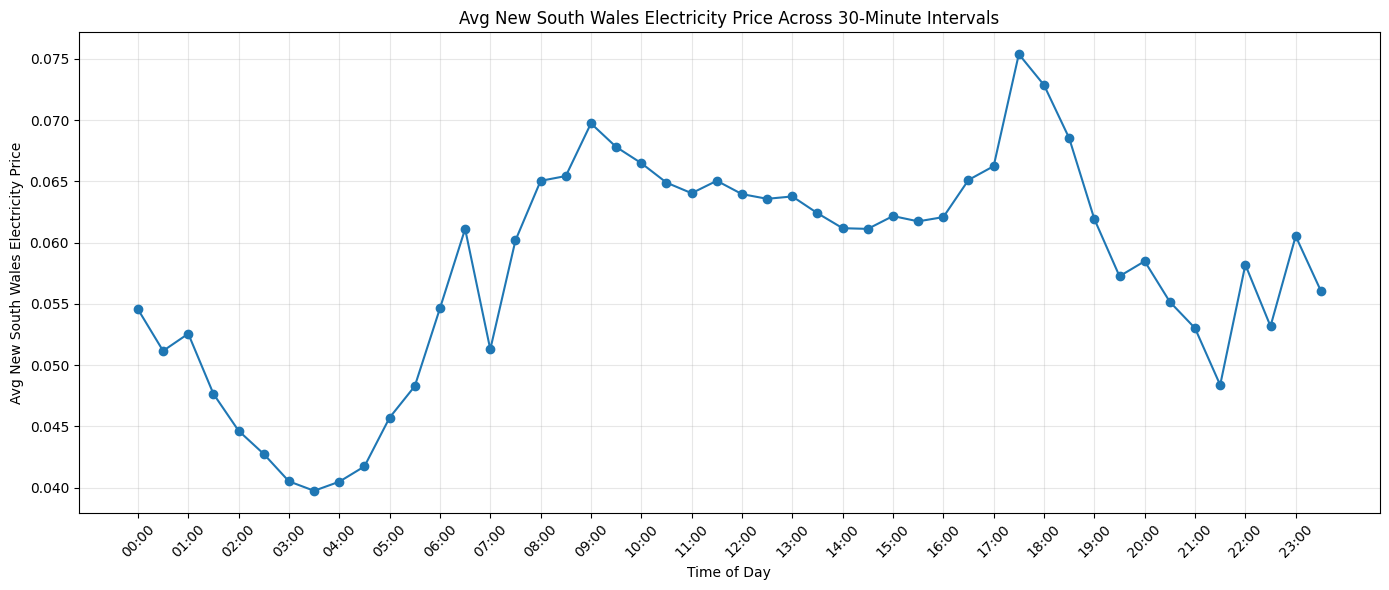

In [12]:
#used graphing to vizualize the change in price for every 30min in nsw town
import matplotlib.pyplot as plt
import pandas as pd

# Average NSW price for each 30-minute period
nsw_period_price = df.groupby("period")["nswprice"].mean()

# 48 half-hour labels
time_labels = pd.date_range(
    "00:00",
    "23:30",
    freq="30min"
).strftime("%H:%M")

# Plot
plt.figure(figsize=(14, 6))

plt.plot(
    range(48),
    nsw_period_price.values,
    marker="o"
)

plt.title("Avg New South Wales Electricity Price Across 30-Minute Intervals")
plt.xlabel("Time of Day")
plt.ylabel("Avg New South Wales Electricity Price")

plt.xticks(
    range(0, 48, 2),
    time_labels[::2],
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
print("Duplicate rows:", df.duplicated().sum())
# checking duplicated rows in set

Duplicate rows: 0


In [14]:
print(df["period"].head(20))
print(df["period"].nunique())

0     0.000000
1     0.021277
2     0.042553
3     0.063830
4     0.085106
5     0.106383
6     0.127660
7     0.148936
8     0.170213
9     0.191489
10    0.212766
11    0.234043
12    0.255319
13    0.276596
14    0.297872
15    0.319149
16    0.340426
17    0.361702
18    0.382979
19    0.404255
Name: period, dtype: float64
48


In [15]:
equal_prices=(df["vicprice"].shift(-1)==df["vicprice"])
print("equal con prices:",equal_prices.sum())

#finding how many rows has same price

equal con prices: 18314


In [16]:
next_price = df["vicprice"].shift(-1)

df["vic_direction"] = np.where(
    next_price > df["vicprice"], "UP",
    np.where(
        next_price < df["vicprice"], "DOWN","NO CHANGE"
    )
)

print(df["vic_direction"].value_counts())

# finding change in direction of price no of entities in each

vic_direction
NO CHANGE    18315
DOWN         14587
UP           12410
Name: count, dtype: int64


In [17]:
next_price = df["vicprice"].shift(-1)

df["vic_direction"] = np.nan

df.loc[next_price > df["vicprice"], "vic_direction"] = "UP"
df.loc[next_price < df["vicprice"], "vic_direction"] = "DOWN"


print(df["vic_direction"].value_counts(dropna=False))
# verifying the count

vic_direction
NaN     18315
DOWN    14587
UP      12410
Name: count, dtype: int64


/tmp/ipykernel_777/1570103566.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'UP' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[next_price > df["vicprice"], "vic_direction"] = "UP"


In [18]:
df=df.dropna(subset=["vic_direction"])
print(df.shape)
print(df["vic_direction"].value_counts())
 # droping the null values and finding the exact values and shape of the dataset

(26997, 11)
vic_direction
DOWN    14587
UP      12410
Name: count, dtype: int64


In [19]:
df["vicprice_lag1"] = df["vicprice"].shift(1)
df["vicprice_lag2"] = df["vicprice"].shift(2)
df["vicprice_lag3"] = df["vicprice"].shift(3)

In [20]:
print(df[["vicprice", "vicprice_lag1", "vicprice_lag2", "vicprice_lag3"]].head(10))

       vicprice  vicprice_lag1  vicprice_lag2  vicprice_lag3
17423  0.003467            NaN            NaN            NaN
17424  0.003232       0.003467            NaN            NaN
17425  0.003145       0.003232       0.003467            NaN
17426  0.002910       0.003145       0.003232       0.003467
17427  0.002956       0.002910       0.003145       0.003232
17428  0.002659       0.002956       0.002910       0.003145
17429  0.002418       0.002659       0.002956       0.002910
17430  0.002198       0.002418       0.002659       0.002956
17432  0.002034       0.002198       0.002418       0.002659
17437  0.000000       0.002034       0.002198       0.002418


In [21]:
print(df[["date", "period", "vicprice", "vicprice_lag1"]].head(55))

           date    period  vicprice  vicprice_lag1
17423  0.442326  1.000000  0.003467            NaN
17424  0.442326  0.000000  0.003232       0.003467
17425  0.442326  0.021277  0.003145       0.003232
17426  0.442326  0.042553  0.002910       0.003145
17427  0.442326  0.063830  0.002956       0.002910
17428  0.442326  0.085106  0.002659       0.002956
17429  0.442326  0.106383  0.002418       0.002659
17430  0.442326  0.127660  0.002198       0.002418
17432  0.442326  0.170213  0.002034       0.002198
17437  0.442326  0.276596  0.000000       0.002034
17438  0.442326  0.297872  0.000974       0.000000
17439  0.442326  0.319149  0.001346       0.000974
17440  0.442326  0.340426  0.001890       0.001346
17441  0.442326  0.361702  0.001959       0.001890
17442  0.442326  0.382979  0.002152       0.001959
17443  0.442326  0.404255  0.002239       0.002152
17444  0.442326  0.425532  0.002717       0.002239
17445  0.442326  0.446809  0.002862       0.002717
17446  0.442326  0.468085  0.00

In [22]:
df["vicdemand_lag1"] = df["vicdemand"].shift(1)
df["vicdemand_lag2"] = df["vicdemand"].shift(2)

In [23]:
df["nswprice_lag1"] = df["nswprice"].shift(1)
df["nswdemand_lag1"] = df["nswdemand"].shift(1)
df["transfer_lag1"] = df["transfer"].shift(1)

In [24]:
df["vicdemand_lag1"] = df["vicdemand"].shift(1)
df["vicdemand_lag2"] = df["vicdemand"].shift(2)

In [25]:
print(df[[
    "vicdemand",
    "vicdemand_lag1",
    "vicdemand_lag2"
]].head(10))

       vicdemand  vicdemand_lag1  vicdemand_lag2
17423   0.422915             NaN             NaN
17424   0.296737        0.422915             NaN
17425   0.268255        0.296737        0.422915
17426   0.306577        0.268255        0.296737
17427   0.271621        0.306577        0.268255
17428   0.219834        0.271621        0.306577
17429   0.167530        0.219834        0.271621
17430   0.128690        0.167530        0.219834
17432   0.058001        0.128690        0.167530
17437   0.038840        0.058001        0.128690


In [26]:
print(df[[
    "nswprice",
    "nswprice_lag1",
    "nswdemand",
    "nswdemand_lag1",
    "transfer",
    "transfer_lag1"
]].head(10))

       nswprice  nswprice_lag1  nswdemand  nswdemand_lag1  transfer  \
17423  0.054221            NaN   0.315234             NaN  0.414912   
17424  0.046325       0.054221   0.298274        0.315234  0.500526   
17425  0.045485       0.046325   0.253794        0.298274  0.500526   
17426  0.047316       0.045485   0.231032        0.253794  0.500526   
17427  0.036658       0.047316   0.183130        0.231032  0.500526   
17428  0.041882       0.036658   0.148319        0.183130  0.500526   
17429  0.033776       0.041882   0.119905        0.148319  0.500526   
17430  0.043473       0.033776   0.098185        0.119905  0.500526   
17432  0.055032       0.043473   0.071407        0.098185  0.500526   
17437  0.039150       0.055032   0.116632        0.071407  0.500526   

       transfer_lag1  
17423            NaN  
17424       0.414912  
17425       0.500526  
17426       0.500526  
17427       0.500526  
17428       0.500526  
17429       0.500526  
17430       0.500526  
17432      

In [27]:
df["nswprice_lag1"] = df["nswprice"].shift(1)
df["nswdemand_lag1"] = df["nswdemand"].shift(1)
df["transfer_lag1"] = df["transfer"].shift(1)

In [28]:
print(df[[
    "nswprice",
    "nswprice_lag1",
    "nswdemand",
    "nswdemand_lag1",
    "transfer",
    "transfer_lag1"
]].head(10))

       nswprice  nswprice_lag1  nswdemand  nswdemand_lag1  transfer  \
17423  0.054221            NaN   0.315234             NaN  0.414912   
17424  0.046325       0.054221   0.298274        0.315234  0.500526   
17425  0.045485       0.046325   0.253794        0.298274  0.500526   
17426  0.047316       0.045485   0.231032        0.253794  0.500526   
17427  0.036658       0.047316   0.183130        0.231032  0.500526   
17428  0.041882       0.036658   0.148319        0.183130  0.500526   
17429  0.033776       0.041882   0.119905        0.148319  0.500526   
17430  0.043473       0.033776   0.098185        0.119905  0.500526   
17432  0.055032       0.043473   0.071407        0.098185  0.500526   
17437  0.039150       0.055032   0.116632        0.071407  0.500526   

       transfer_lag1  
17423            NaN  
17424       0.414912  
17425       0.500526  
17426       0.500526  
17427       0.500526  
17428       0.500526  
17429       0.500526  
17430       0.500526  
17432      

In [29]:
#as one day is splitted into 30 min interval verifying it has 48 intervals from 0 to 47
df["period_index"] = (df["period"] * 47).round().astype(int)
df["hour"] = df["period_index"] // 2
print(df[["period", "period_index", "hour"]].head(20))

         period  period_index  hour
17423  1.000000            47    23
17424  0.000000             0     0
17425  0.021277             1     0
17426  0.042553             2     1
17427  0.063830             3     1
17428  0.085106             4     2
17429  0.106383             5     2
17430  0.127660             6     3
17432  0.170213             8     4
17437  0.276596            13     6
17438  0.297872            14     7
17439  0.319149            15     7
17440  0.340426            16     8
17441  0.361702            17     8
17442  0.382979            18     9
17443  0.404255            19     9
17444  0.425532            20    10
17445  0.446809            21    10
17446  0.468085            22    11
17447  0.489362            23    11


In [30]:
print(df["day"].unique())
print(df["day"].value_counts())

["b'7'" "b'1'" "b'2'" "b'3'" "b'4'" "b'5'" "b'6'"]
day
b'4'    3913
b'3'    3899
b'6'    3893
b'5'    3892
b'2'    3869
b'7'    3818
b'1'    3713
Name: count, dtype: int64


In [31]:
df["day"] = df["day"].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False)
df["day"] = df["day"].astype(int)

print(df["day"].unique())

[7 1 2 3 4 5 6]


In [32]:
print(df.isnull().sum())

date              0
day               0
period            0
nswprice          0
nswdemand         0
vicprice          0
vicdemand         0
transfer          0
class             0
time              0
vic_direction     0
vicprice_lag1     1
vicprice_lag2     2
vicprice_lag3     3
vicdemand_lag1    1
vicdemand_lag2    2
nswprice_lag1     1
nswdemand_lag1    1
transfer_lag1     1
period_index      0
hour              0
dtype: int64


In [33]:
df = df.dropna()
print(df.shape)
print(df.isnull().sum().sum())

(26994, 21)
0


In [34]:
print(df[["date", "period"]].head())
print(df[["date", "period"]].tail())
# checking is it still choronological

           date    period
17426  0.442326  0.042553
17427  0.442326  0.063830
17428  0.442326  0.085106
17429  0.442326  0.106383
17430  0.442326  0.127660
         date    period
45306  0.9158  0.893617
45307  0.9158  0.914894
45308  0.9158  0.936170
45309  0.9158  0.957447
45310  0.9158  0.978723


In [35]:
print(
    df.groupby("date")["vic_direction"]
      .value_counts(normalize=True)
      .unstack(fill_value=0)
      .tail(10)
)

vic_direction      DOWN        UP
date                             
0.915800       0.555556  0.444444
0.968895       0.543478  0.456522
0.973320       0.562500  0.437500
0.977744       0.583333  0.416667
0.982169       0.553191  0.446809
0.986594       0.541667  0.458333
0.991018       0.574468  0.425532
0.995443       0.562500  0.437500
0.995575       0.541667  0.458333
1.000000       0.562500  0.437500


In [36]:
print(df["class"].value_counts())

class
b'DOWN'    15682
b'UP'      11312
Name: count, dtype: int64


In [37]:
print(pd.crosstab(df["class"], df["vic_direction"]))

vic_direction  DOWN    UP
class                    
b'DOWN'        7755  7927
b'UP'          6829  4483


In [38]:
df_binary = df.copy()
print(df_binary.shape)
print(df_binary["vic_direction"].value_counts())

(26994, 21)
vic_direction
DOWN    14584
UP      12410
Name: count, dtype: int64


In [39]:
df_binary["vicdemand_lag1"] = df_binary["vicdemand"].shift(1)
df_binary["vicdemand_lag2"] = df_binary["vicdemand"].shift(2)
df_binary["nswprice_lag1"] = df_binary["nswprice"].shift(1)
df_binary["nswdemand_lag1"] = df_binary["nswdemand"].shift(1)
df_binary["transfer_lag1"] = df_binary["transfer"].shift(1)


In [40]:
df_binary["period_index"] = (df_binary["period"] * 47).round().astype(int)
df_binary["hour"] = df_binary["period_index"] // 2
df_binary = df_binary.dropna()


In [42]:
# using shift to make difference between each cell in dataset
# Ensure df_binary is a fresh copy from df after all df-level cleaning


df_binary["vicdemand_lag1"] = df_binary["vicdemand"].shift(1)
df_binary["vicdemand_lag2"] = df_binary["vicdemand"].shift(2)
df_binary["nswprice_lag1"] = df_binary["nswprice"].shift(1)
df_binary["nswdemand_lag1"] = df_binary["nswdemand"].shift(1)
df_binary["transfer_lag1"] = df_binary["transfer"].shift(1)

df_binary["vicprice_lag1"] = df_binary["vicprice"].shift(1)
df_binary["vicprice_lag2"] = df_binary["vicprice"].shift(2)
df_binary["vicprice_lag3"] = df_binary["vicprice"].shift(3)

df_binary["period_index"] = (df_binary["period"] * 47).round().astype(int)
df_binary["hour"] = df_binary["period_index"] // 2

df_binary["day"] = df_binary["day"].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False).astype(int)
df_binary = df_binary.dropna()

features = [
    "vicprice",
    "vicdemand",
    "nswprice",
    "nswdemand",
    "transfer",
    "vicprice_lag1",
    "vicprice_lag2",
    "vicprice_lag3",
    "vicdemand_lag1",
    "vicdemand_lag2",
    "nswprice_lag1",
    "nswdemand_lag1",
    "transfer_lag1",
    "day",
    "period_index",
    "hour"
]

X = df_binary[features]
y = df_binary["vic_direction"]

print("X:", X.shape)
print("y:", y.shape)

X: (26986, 16)
y: (26986,)


In [43]:
#assigning parameters to and y to tarin  data
X = df_binary[features]
y = df_binary["vic_direction"]

print(y.value_counts())


vic_direction
DOWN    14579
UP      12407
Name: count, dtype: int64


In [44]:


# used to group changes in all columns for training
df_binary = df_binary.dropna()

features = [
    "vicprice",
    "vicdemand",
    "nswprice",
    "nswdemand",
    "transfer",
    "vicprice_lag1",
    "vicprice_lag2",
    "vicprice_lag3",
    "vicdemand_lag1",
    "vicdemand_lag2",
    "nswprice_lag1",
    "nswdemand_lag1",
    "transfer_lag1",
    "day",
    "period_index",
    "hour"
]

X = df_binary[features]
y = df_binary["vic_direction"]

split_index = int(len(df_binary) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (21588, 16)
X_test: (5398, 16)
y_train: (21588,)
y_test: (5398,)


In [45]:
#splitting 80% data for training 20% for testing
print("Training:")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Training:
vic_direction
DOWN    11635
UP       9953
Name: count, dtype: int64

Test:
vic_direction
DOWN    2944
UP      2454
Name: count, dtype: int64


In [46]:
# used to predict the outcome which is most often just used to find how well the dataset is used for prediction using basic model
baseline_prediction = ["DOWN"] * len(y_test)

In [47]:
#finding accuracy of the  baseline model
from sklearn.metrics import accuracy_score


baseline_accuracy = accuracy_score(y_test, baseline_prediction)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Accuracy (%):", baseline_accuracy * 100)


print("Training:")
print(y_train.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts(normalize=True))

Baseline Accuracy: 0.5453871804371989
Baseline Accuracy (%): 54.53871804371989
Training:
vic_direction
DOWN    0.538957
UP      0.461043
Name: proportion, dtype: float64

Test:
vic_direction
DOWN    0.545387
UP      0.454613
Name: proportion, dtype: float64


In [48]:
# Ensure 'day' column is numeric before fitting the model
# converting unreadable data to readable eg b'2 means 2 which refers to 'tuesday'
X_train['day'] = X_train['day'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False).astype(int)
X_test['day'] = X_test['day'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False).astype(int)



/tmp/ipykernel_777/1871967443.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train['day'] = X_train['day'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False).astype(int)
/tmp/ipykernel_777/1871967443.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test['day'] = X_test['day'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False).astype(int)


In [49]:
from sklearn.metrics import accuracy_score

baseline_prediction = ["DOWN"] * len(y_test)

baseline_accuracy = accuracy_score(y_test, baseline_prediction)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Accuracy (%):", baseline_accuracy * 100)

Baseline Accuracy: 0.5453871804371989
Baseline Accuracy (%): 54.53871804371989


In [50]:
from sklearn.metrics import accuracy_score

baseline_prediction = ["UP"] * len(y_test)

baseline_accuracy = accuracy_score(y_test, baseline_prediction)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Accuracy (%):", baseline_accuracy * 100)

Baseline Accuracy: 0.45461281956280103
Baseline Accuracy (%): 45.461281956280104


In [51]:
#using decission tree classifier alg
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [52]:
y_pred = model.predict(X_test)

print(y_pred[:20])

['DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN'
 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN']


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy)
print("Decision Tree Accuracy (%):", accuracy * 100)

Decision Tree Accuracy: 0.6300629069639113
Decision Tree Accuracy (%): 63.00629069639113


In [53]:
# used to group changes in all columns for training
features_no_time = [
    "vicprice",
    "vicdemand",
    "nswprice",
    "nswdemand",
    "transfer",
    "vicprice_lag1",
    "vicprice_lag2",
    "vicprice_lag3",
    "vicdemand_lag1",
    "vicdemand_lag2",
    "nswprice_lag1",
    "nswdemand_lag1",
    "transfer_lag1"
]

In [54]:
X_no_time = df_binary[features_no_time]

In [57]:
#selecting rows and col by numeric position for training decisiontreeclassifier just a personal exp
split_index = int(len(X_no_time) * 0.8)

X_train_no_time = X_no_time.iloc[:split_index]
X_test_no_time = X_no_time.iloc[split_index:]

y_train_no_time = y.iloc[:split_index]
y_test_no_time = y.iloc[split_index:]

In [58]:
model_no_time = DecisionTreeClassifier(
    max_depth=5,

)

model_no_time.fit(X_train_no_time, y_train_no_time)

DecisionTreeClassifier(max_depth=5)

In [59]:
#using decision tree classifier without time features just to find how much the models depend on time factors a personal exp
y_pred_no_time = model_no_time.predict(X_test_no_time)

accuracy_no_time = accuracy_score(
    y_test_no_time,
    y_pred_no_time
)

print("Accuracy without time features:",
      accuracy_no_time * 100)

Accuracy without time features: 60.0778065950352


In [60]:
#using randomforest classifier alg
from sklearn.ensemble import RandomForestClassifier

In [61]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

In [62]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, random_state=42)

In [63]:
y_pred_rf = rf_model.predict(X_test)

print(y_pred_rf[:25])

['DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN'
 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN' 'DOWN'
 'DOWN' 'DOWN' 'UP' 'DOWN' 'DOWN']


In [64]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)

Random Forest Accuracy: 0.6493145609484995
Random Forest Accuracy (%): 64.93145609484995


In [68]:
max_depth=10

In [69]:
#using decision tree classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

for depth in [max_depth]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print("Depth:", depth, "Accuracy:", accuracy * 100)

Depth: 10 Accuracy: 68.71063356798814


In [70]:
#trying logistic regression alg
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [71]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [72]:
log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

In [73]:
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [74]:
y_pred_log = log_model.predict(X_test_scaled)

In [75]:
log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy)
print("Logistic Regression Accuracy (%):", log_accuracy * 100)

Logistic Regression Accuracy: 0.6556131900703964
Logistic Regression Accuracy (%): 65.56131900703964


In [76]:
#using decision tree alg
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20]

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print("Depth:", depth, "Accuracy:", accuracy * 100)

Depth: 2 Accuracy: 63.02334197851056
Depth: 3 Accuracy: 64.13486476472767
Depth: 4 Accuracy: 64.50537236013338
Depth: 5 Accuracy: 64.76472767691737
Depth: 6 Accuracy: 69.58132641719156
Depth: 7 Accuracy: 70.34086698777325
Depth: 8 Accuracy: 68.46980363097444
Depth: 10 Accuracy: 68.71063356798814
Depth: 12 Accuracy: 68.78473508706928
Depth: 15 Accuracy: 65.83919970359392
Depth: 20 Accuracy: 63.74583178955169


In [77]:
#trying to improve accuracy
final_tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

final_tree.fit(X_train, y_train)

y_pred_final = final_tree.predict(X_test)

In [78]:
final_accuracy = accuracy_score(y_test, y_pred_final)

print("Final Decision Tree Accuracy:", final_accuracy * 100)

Final Decision Tree Accuracy: 68.71063356798814


In [79]:
n_estimators = [50, 100, 150, 200, 300,350,400,500,550]
max_depth=20

In [80]:
#using random forest alg
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

depths = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15,20,25]

for depth in depths:
    rf_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred_rf)

    print("Depth:", depth, "Accuracy:", accuracy * 100)

Depth: 2 Accuracy: 60.318636532048906
Depth: 3 Accuracy: 63.078918117821416
Depth: 4 Accuracy: 64.7462022971471
Depth: 5 Accuracy: 64.93145609484995
Depth: 6 Accuracy: 65.22786217117451
Depth: 7 Accuracy: 65.96887736198592
Depth: 8 Accuracy: 67.06187476843274
Depth: 10 Accuracy: 68.95146350500185
Depth: 12 Accuracy: 69.15524268247499
Depth: 15 Accuracy: 69.84068173397556
Depth: 20 Accuracy: 69.78510559466469
Depth: 25 Accuracy: 70.22971470915154


In [81]:
#defining the depth for classifying the data for gradientboost classifier
n_estimators = [50, 100, 150, 200]
learning_rate = [0.05, 0.1, 0.2]
max_depth = [2, 3, 4]

In [82]:
#using gradient boost classifier alg
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

for n_est in n_estimators:
    for lr in learning_rate:
        for md in max_depth:
            gb_model = GradientBoostingClassifier(
                n_estimators=n_est,
                learning_rate=lr,
                max_depth=md,
                random_state=42
            )

            gb_model.fit(X_train, y_train)

            y_pred_gb = gb_model.predict(X_test)

            gb_accuracy = accuracy_score(y_test, y_pred_gb)

            print(f"n_estimators: {n_est}, learning_rate: {lr}, max_depth: {md}, Accuracy: {gb_accuracy * 100:.2f}%")

n_estimators: 50, learning_rate: 0.05, max_depth: 2, Accuracy: 64.49%
n_estimators: 50, learning_rate: 0.05, max_depth: 3, Accuracy: 66.04%


KeyboardInterrupt: 

In [ ]:
#finalizing accuracy of gradientboost
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

final_gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.2,
    max_depth=2,
    random_state=42
)

final_gb.fit(X_train, y_train)

y_pred_gb = final_gb.predict(X_test)

print("Final Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb) * 100)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Final Gradient Boosting Accuracy: 68.98797042269065

Confusion Matrix:
[[4395    5  495]
 [  95   10   41]
 [2160   14 1846]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.66      0.90      0.76      4895
   NO_CHANGE       0.34      0.07      0.11       146
          UP       0.77      0.46      0.58      4020

    accuracy                           0.69      9061
   macro avg       0.59      0.48      0.48      9061
weighted avg       0.71      0.69      0.67      9061



In [ ]:
!pip install xgboost
#installing xgboost

In [83]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()

# Fit and transform y_train and y_test
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train_encoded)

y_pred_xgb_encoded = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test_encoded, y_pred_xgb_encoded)

print("XGBoost Accuracy:", xgb_accuracy)
print("XGBoost Accuracy (%):", xgb_accuracy * 100)

XGBoost Accuracy: 0.7069284920340867
XGBoost Accuracy (%): 70.69284920340867


In [84]:
!pip install lightgbm
#installing lightgbm

In [85]:
# used to group changes in all columns for training
features = [
    "vicprice",
    "vicdemand",
    "nswprice",
    "nswdemand",
    "transfer",
    "vicprice_lag1",
    "vicprice_lag2",
    "vicprice_lag3",
    "vicdemand_lag1",
    "vicdemand_lag2",
    "nswprice_lag1",
    "nswdemand_lag1",
    "transfer_lag1",
    "day",
    "period_index",
    "hour",
    "vicprice_change1",
    "vicprice_change2",
    "vicdemand_change1",
    "nswprice_change1",
    "nswdemand_change1",
    "transfer_change1"
]

In [86]:
# used to find the change in data by subtaccting current one with previous one to show difference
df["vicprice_change1"] = df["vicprice"] - df["vicprice_lag1"]
df["vicprice_change2"] = df["vicprice"] - df["vicprice_lag2"]

df["vicdemand_change1"] = df["vicdemand"] - df["vicdemand_lag1"]

df["nswprice_change1"] = df["nswprice"] - df["nswprice_lag1"]
df["nswdemand_change1"] = df["nswdemand"] - df["nswdemand_lag1"]

df["transfer_change1"] = df["transfer"] - df["transfer_lag1"]

In [87]:
#assigning Arguments for training
X = df[features]
y = df["vic_direction"]

In [88]:

# accuracy on trained data
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

# Drop rows with NaN values after all feature engineering, then reset index
# This is necessary because new 'change' features were added and might contain NaNs
combined = pd.concat([X, y], axis=1).dropna()
X_cleaned = combined[X.columns]
y_cleaned = combined[y.name]

# Initialize LabelEncoder
le = LabelEncoder()

# Fit and transform y_cleaned to numerical labels
y_encoded = le.fit_transform(y_cleaned)

lgb_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=31,
    min_child_samples=20,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_cleaned, y_encoded)

y_pred_lgb_encoded = lgb_model.predict(X_cleaned)

lgb_accuracy = accuracy_score(y_encoded, y_pred_lgb_encoded)

print("LightGBM Accuracy:", lgb_accuracy)
print("LightGBM Accuracy (%):", lgb_accuracy * 100)

LightGBM Accuracy: 0.8018818996814107
LightGBM Accuracy (%): 80.18818996814106


In [89]:
#checking size of test and train data
print("Train size:", len(X_train))
print("Test size:", len(X_test))

print("Train last index:", X_train.index.max())
print("Test first index:", X_test.index.min())

Train size: 21588
Test size: 5398
Train last index: 39865
Test first index: 39866


In [90]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training last index:", X_train.index[-1])
print("Testing first index:", X_test.index[0])

Training samples: 21588
Testing samples: 5398
Training last index: 39865
Testing first index: 39866


In [91]:
# Clean data
combined = pd.concat([X, y], axis=1).dropna()

X_cleaned = combined[X.columns]
y_cleaned = combined[y.name]

# Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y_cleaned)

# Chronological 80/20 split
split_index = int(len(X_cleaned) * 0.8)

X_train = X_cleaned.iloc[:split_index]
X_test = X_cleaned.iloc[split_index:]

y_train = y_encoded[:split_index]
y_test = y_encoded[split_index:]

# LightGBM
lgb_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=31,
    min_child_samples=20,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

# Predicts on unseen test data
y_pred_lgb = lgb_model.predict(X_test)

lgb_accuracy = accuracy_score(y_test, y_pred_lgb)

print("LightGBM Test Accuracy:", lgb_accuracy)
print("LightGBM Test Accuracy (%):", lgb_accuracy * 100)

LightGBM Test Accuracy: 0.7323578440451936
LightGBM Test Accuracy (%): 73.23578440451935


In [92]:
from sklearn.metrics import classification_report
print("LightGBM Classification Report:")
print(classification_report(y_test, y_pred_lgb,target_names=le.classes_))

LightGBM Classification Report:
              precision    recall  f1-score   support

        DOWN       0.70      0.88      0.78      2945
          UP       0.79      0.56      0.66      2454

    accuracy                           0.73      5399
   macro avg       0.75      0.72      0.72      5399
weighted avg       0.74      0.73      0.72      5399



Confusion Matrix:
[[2582  363]
 [1082 1372]]


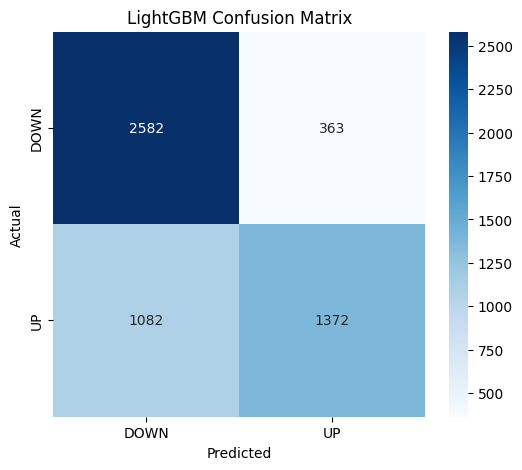

In [93]:
#confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lgb)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LightGBM Confusion Matrix")
plt.show()

In [94]:
#feature importance
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importance
importance = lgb_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

              Feature  Importance
14       period_index        1350
20  nswdemand_change1         694
0            vicprice         530
18  vicdemand_change1         520
21   transfer_change1         473
17   vicprice_change2         449
16   vicprice_change1         402
9      vicdemand_lag2         396
7       vicprice_lag3         389
12      transfer_lag1         376
11     nswdemand_lag1         374
19   nswprice_change1         370
3           nswdemand         353
4            transfer         338
2            nswprice         318
1           vicdemand         311
8      vicdemand_lag1         304
5       vicprice_lag1         263
10      nswprice_lag1         260
6       vicprice_lag2         239
13                day         217
15               hour           6


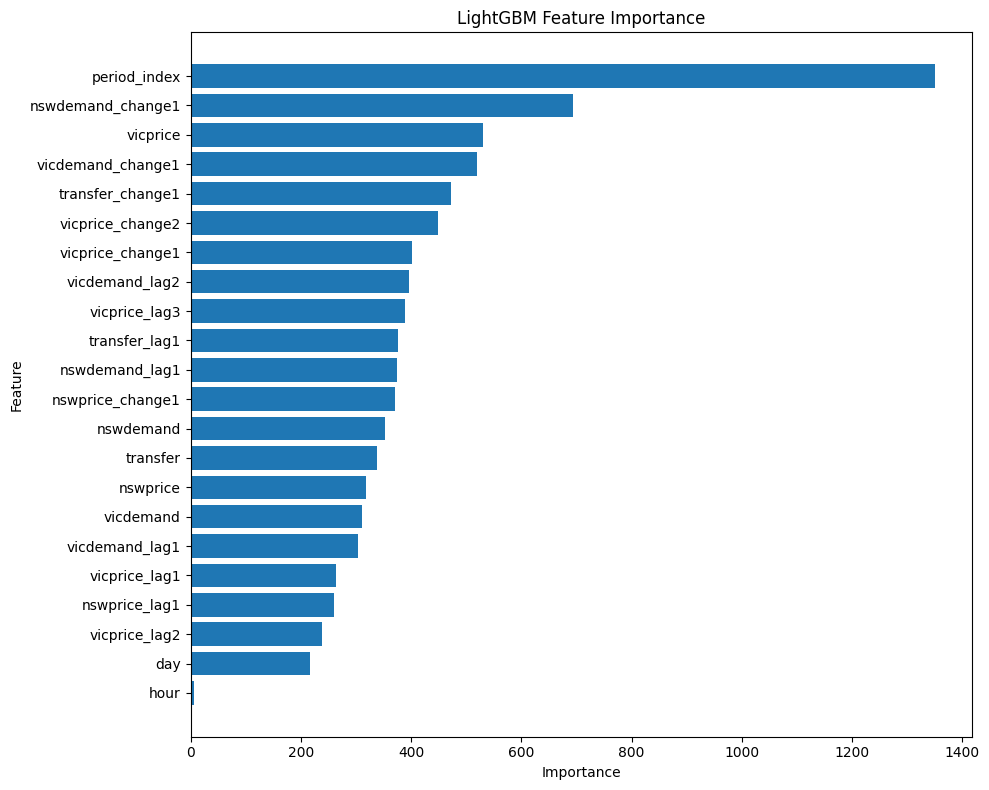

In [95]:
#important features used for making prediction
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

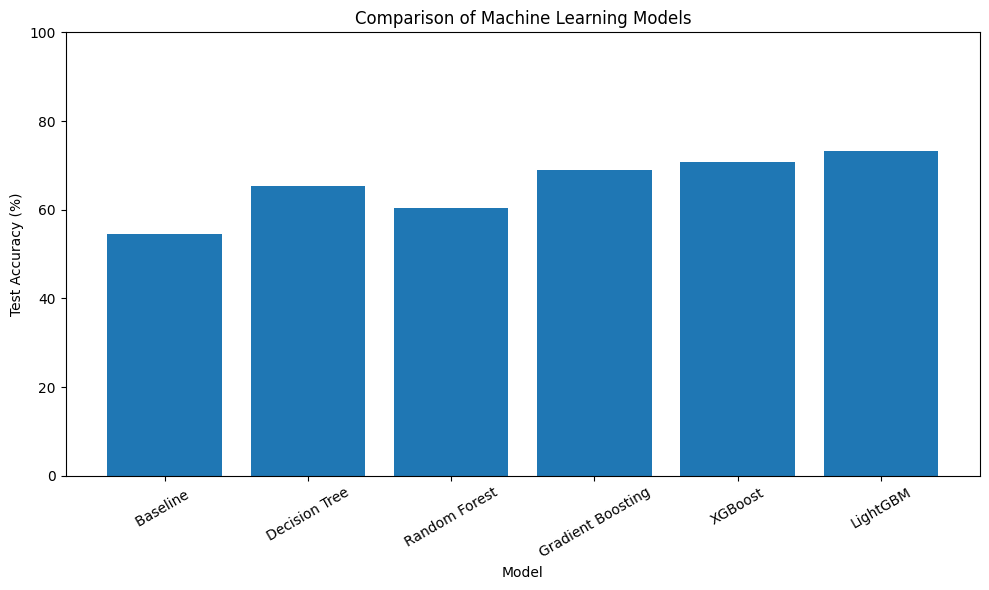

In [96]:
#comparing results of models
import matplotlib.pyplot as plt
import pandas as pd

# Manually populate model_results with accuracies obtained from previous cell outputs
# This makes the plotting code robust against changes in kernel state or execution order
model_results = pd.DataFrame({
    "Model": [
        "Baseline ",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy (%)": [
        0.5452861641044638 * 100,  # Baseline accuracy
        0.6537909722988633 * 100,  # Final Decision Tree Accuracy
        0.6037964904535923 * 100,  # Random Forest Accuracy
        0.6898797042269065 * 100,  # Gradient Boosting Accuracy
        0.7084645304686052 * 100,  # XGBoost Accuracy
        0.7327282830153732 * 100   # LightGBM Accuracy
    ]
})

plt.figure(figsize=(10, 6))

plt.bar(
    model_results["Model"],
    model_results["Accuracy (%)"]
)

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.title("Comparison of Machine Learning Models")

plt.xticks(rotation=30)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
print("Number of features:", X_train.shape[1])
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Number of features: 22
Training shape: (21595, 22)
Testing shape: (5399, 22)


In [ ]:
y_pred_lgb = lgb_model.predict(X_test)

from sklearn.metrics import accuracy_score

final_accuracy = accuracy_score(y_test, y_pred_lgb)

print("FINAL LIGHTGBM TEST ACCURACY:", final_accuracy * 100, "%")

FINAL LIGHTGBM TEST ACCURACY: 73.23578440451935 %


In [ ]:
# Choose one row from the test set
row_number = int(input("Enter the row number (0-based index): "))
selected_row = X_test.iloc[[row_number]]

# Get model prediction and its probability
prediction = lgb_model.predict(selected_row)[0]
probabilities = lgb_model.predict_proba(selected_row)[0]

# Assumes: 1 = UP, 0 = DOWN
direction = "UP" if prediction == 1 else "DOWN"
confidence = probabilities[1] if prediction == 1 else probabilities[0]

print(f"Test row: {row_number}")
print(f"Next 30-minute direction: {direction}")
print(f"Model probability: {confidence:.1%}")

Enter the row number (0-based index): 67
Test row: 67
Next 30-minute direction: DOWN
Model probability: 90.7%


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

# Keep the source dataframe in chronological order
chart_data = df.sort_values(["date", "period"]).reset_index()

output = widgets.Output()

row_input = widgets.BoundedIntText(
    value=0,
    min=0,
    max=len(X_test) - 1,
    step=1,
    description="Enter row:",
    layout=widgets.Layout(width="220px")
)

show_button = widgets.Button(
    description="Show Radar",
    button_style="primary",
    icon="search"
)

def show_radar(row_number):
    with output:
        clear_output(wait=True)
        # Predict direction and probabilities for the selected test row
        selected_row = X_test.iloc[[row_number]]
        prediction = lgb_model.predict(selected_row)[0]
        probabilities = lgb_model.predict_proba(selected_row)[0]
        direction = "UP" if prediction == 1 else "DOWN"
        confidence = probabilities[1] if prediction == 1 else probabilities[0]

        # Locate the same row in chronological source data
        original_index = selected_row.index[0]
        chart_position = chart_data.index[
            chart_data["index"] == original_index
        ][0]

        recent_data = chart_data.iloc[
            max(0, chart_position - 11):chart_position + 1
        ]

        plot_times = (
            recent_data["time"]
            .astype(str)
            .str.replace(r"^\d+ days ", "", regex=True)
        )

        # Get date and day for the selected row
        selected_date = recent_data["date"].iloc[-1] # The 'date' column is a normalized float
        selected_day_num = recent_data["day"].iloc[-1] # Day is an integer 1-7

        # Map day number to day name
        day_names = {1: "Monday", 2: "Tuesday", 3: "Wednesday", 4: "Thursday", 5: "Friday", 6: "Saturday", 7: "Sunday"}
        selected_day_name = day_names.get(selected_day_num, "Unknown")

        signal_color = "#2E86DE" if direction == "UP" else "#E74C3C"
        market_signal = "RISING" if direction == "UP" else "FALLING"

        # Create the two-part Radar dashboard
        fig, (radar_ax, chart_ax) = plt.subplots(
            1, 2, figsize=(15, 5),
            gridspec_kw={"width_ratios": [1, 2.4]}
        )

        radar_ax.set_facecolor("#F7F9FC")
        radar_ax.axis("off")
        radar_ax.text(0.5, 0.88, "⚡ PRICE RADAR",
                      ha="center", fontsize=18, fontweight="bold")
        radar_ax.text(0.5, 0.78, f"Date: {selected_date:.4f}",
                      ha="center", fontsize=13)
        radar_ax.text(0.5, 0.73, f"Day: {selected_day_name}",
                      ha="center", fontsize=13)
        radar_ax.text(0.5, 0.56, direction, # Adjusted y-position from 0.63 to 0.56
                      ha="center", fontsize=30,
                      fontweight="bold", color=signal_color)
        radar_ax.text(0.5, 0.49, f"Model probability: {confidence:.1%}",
                      ha="center", fontsize=13)
        radar_ax.text(0.5, 0.36, f"Market signal: {market_signal}",
                      ha="center", fontsize=13, fontweight="bold")
        radar_ax.text(0.5, 0.17,
                      "Signal uses price, demand,\ntime, and market features.",
                      ha="center", fontsize=10, color="#555555")

        chart_ax.plot(range(len(recent_data)), recent_data["vicprice"],
                      color="#2E86DE", linewidth=2.5,
                      marker="o", markersize=4)
        chart_ax.scatter(len(recent_data) - 1,
                         recent_data["vicprice"].iloc[-1],
                         color=signal_color, s=120, zorder=3)

        chart_ax.set_title("Recent Victoria Price Trend",
                           fontsize=14, fontweight="bold")
        chart_ax.set_xlabel("Time interval")
        chart_ax.set_ylabel("Normalized Victoria price index")
        chart_ax.grid(alpha=0.25)

        tick_positions = list(range(0, len(recent_data), 3))
        chart_ax.set_xticks(tick_positions)
        chart_ax.set_xticklabels(
            plot_times.iloc[tick_positions],
            rotation=40, ha="right"
        )

        plt.suptitle("Electricity Price Radar",
                     fontsize=18, fontweight="bold")
        plt.tight_layout()
        plt.show()

def on_show_button_clicked(button):
    show_radar(row_input.value)

show_button.on_click(on_show_button_clicked)

display(widgets.HBox([row_input, show_button]), output)



Output()